> **Portfolio summary:** Are gold and oil futures returns normal? Normality tests, Student-t fits and volatility clustering (group project).
>
> [Project README](README.md) · [Back to the portfolio](../README.md)

## Statistical diagnosis of financial data

### Normality and dependence diagnostics using Gold and Oil returns

We use Gold (GC=F) and Crude Oil (CL=F) futures from Yahoo Finance, two non-stock financial assets, to run an exploratory data analysis of returns and log returns.

Note: WTI front-month futures settled at a negative price on 20 April 2020. A negative price makes the log return undefined and breaks the lecture property that a net return cannot fall below -1. We clean that episode out before any diagnostics and also re-run the tests with the whole of April 2020 removed as a robustness check.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import yfinance as yf

# Plots
from IPython import get_ipython
ip = get_ipython()
if ip is not None:
    ip.run_line_magic("matplotlib", "inline")

plt.rc("font", size=16)
plt.rc("axes", titlesize=16, labelsize=16)
plt.rc("xtick", labelsize=14)
plt.rc("ytick", labelsize=14)

BASE_DIR = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(BASE_DIR / "mplconfig"))

'data/ slides/mplconfig'

## 1. Download prices and compute returns

We download daily close prices for Gold (GC=F) and Crude Oil (CL=F) futures.

Futures do not pay dividends, so the plain close is the correct price to use here (no dividend adjustment needed, unlike the stock case in the lecture).

**Net returns:**
$$R_t = \frac{P_t - P_{t-1}}{P_{t-1}}$$

**Log returns:**
$$r_t = \ln\!\left(\frac{P_t}{P_{t-1}}\right)$$

In [2]:
tickers = {"GC=F": "Gold", "CL=F": "Oil"}
raw = yf.download(list(tickers.keys()), start="2019-01-01", end="2024-12-31")["Close"]
raw = raw.dropna()
raw.columns = [tickers[c] for c in raw.columns]

# Keep only days where every price is strictly positive.
# This removes the 20 Apr 2020 negative WTI settlement.
p = raw[(raw > 0).all(axis=1)].copy()

removed = raw.index.difference(p.index)
print(f"Rows removed for non-positive prices: {len(removed)}")
if len(removed):
    print("Dates:", [d.date() for d in removed])
p.head()

Rows removed for non-positive prices: 1
Dates: [datetime.date(2020, 4, 20)]

,Oil,Gold
Date,,
2019-01-02,46.540001,1281.000000
2019-01-03,47.090000,1291.800049
2019-01-04,47.959999,1282.699951
2019-01-07,48.520000,1286.800049
2019-01-08,49.779999,1283.199951


In [3]:
# Returns. After dropping bad price days there can be calendar gaps.
# A return computed across a gap is not a true one-day return, so we drop it.
gap = p.index.to_series().diff().dt.days > 5

r = p.pct_change()
log_r = np.log(p / p.shift(1))

r = r[~gap].dropna()
log_r = log_r[~gap].dropna()

# Use the same set of dates for net and log returns so the two are comparable.
common = r.index.intersection(log_r.index)
r = r.loc[common]
log_r = log_r.loc[common]

print(f"Sample: {r.index.min().date()} to {r.index.max().date()}, n = {len(r)}")
print("\nNet returns:")
display(r.head())
print("\nLog returns:")
display(log_r.head())

Sample: 2019-01-03 to 2024-12-30, n = 1507

Net returns:

,Oil,Gold
Date,,
2019-01-03,0.011818,0.008431
2019-01-04,0.018475,-0.007045
2019-01-07,0.011676,0.003196
2019-01-08,0.025969,-0.002798
2019-01-09,0.051828,0.004754



Log returns:

,Oil,Gold
Date,,
2019-01-03,0.011748,0.008396
2019-01-04,0.018307,-0.007069
2019-01-07,0.011609,0.003191
2019-01-08,0.025637,-0.002802
2019-01-09,0.050530,0.004743


## 2. First look: prices vs returns

- **Prices** often look nonstationary (trends, level shifts).
- **Returns** are usually closer to stationary and are the standard object for distributional diagnostics.
- We plot both net returns and log-returns.

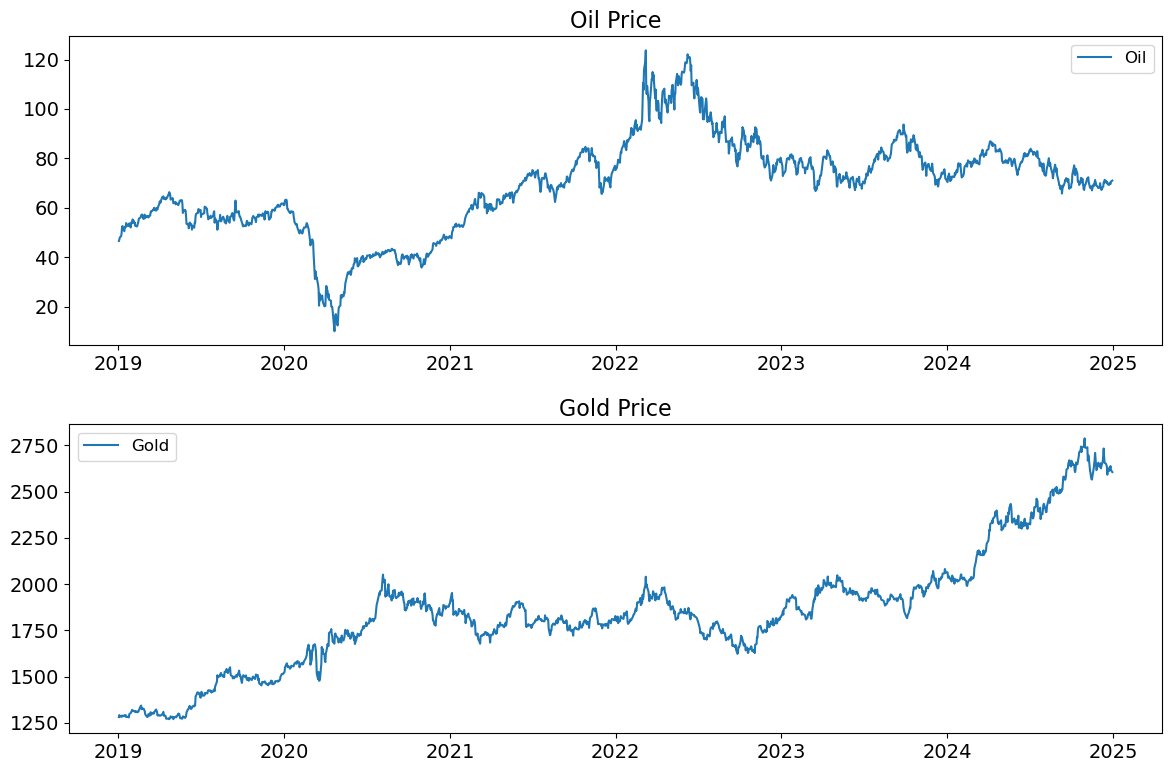

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(12, 8))
for i, comp in enumerate(p.columns):
    axs[i].plot(p.index, p[comp], label=comp)
    axs[i].set_title(f"{comp} Price")
    axs[i].legend(fontsize=12)
fig.tight_layout()
fig.savefig(BASE_DIR / "Commodity price.png", dpi=200)
plt.show()

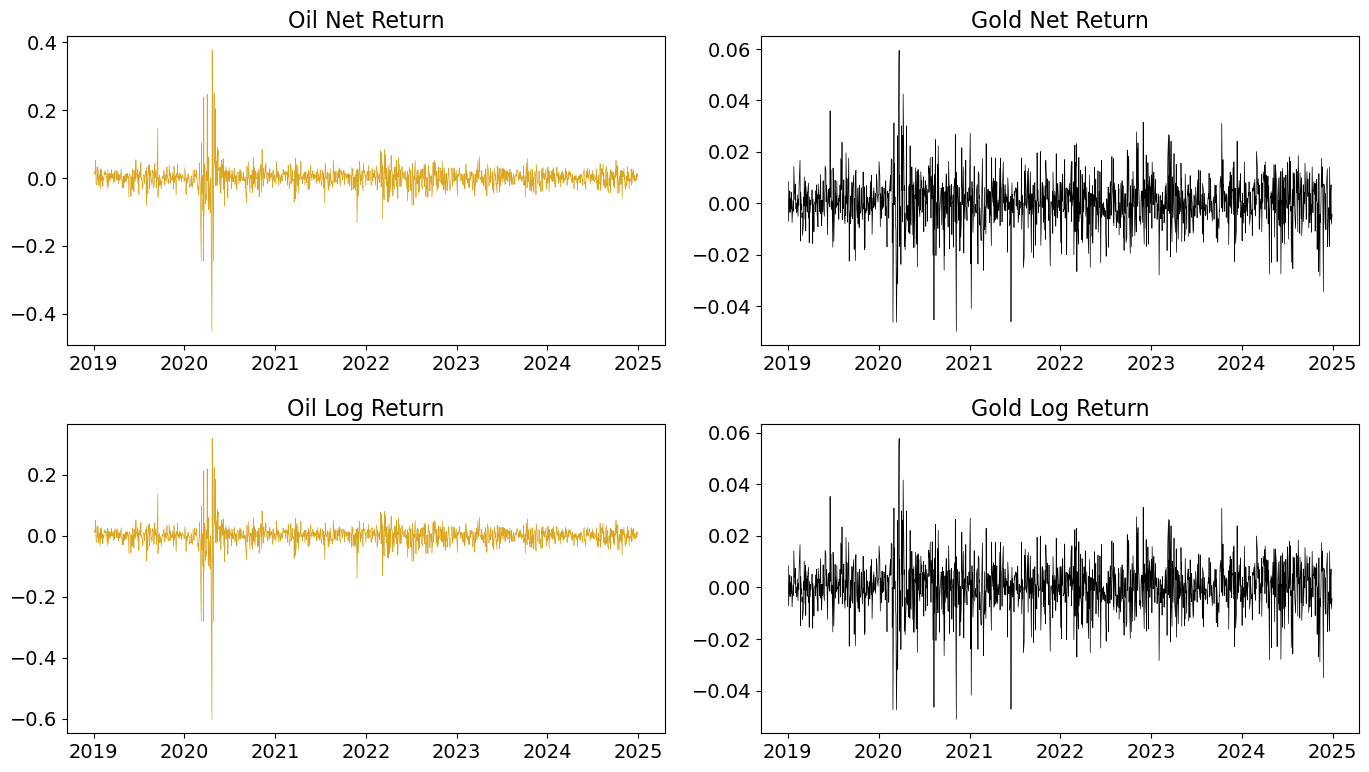

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(14, 8))
col = ["goldenrod", "black"]
for i, comp in enumerate(r.columns):
    axs[0, i].plot(r.index, r[comp], color=col[i], linewidth=0.5)
    axs[0, i].set_title(f"{comp} Net Return")
    axs[1, i].plot(log_r.index, log_r[comp], color=col[i], linewidth=0.5)
    axs[1, i].set_title(f"{comp} Log Return")
fig.tight_layout()
fig.savefig(BASE_DIR / "Commodity return.png", dpi=200)
plt.show()

## 3. Visual normality diagnostics (univariate)

We use:

- **Histogram**: shape, skewness, tails
- **Normal Q–Q plot**: deviations from a straight line indicate non-Normality

We check both net returns and log-returns.

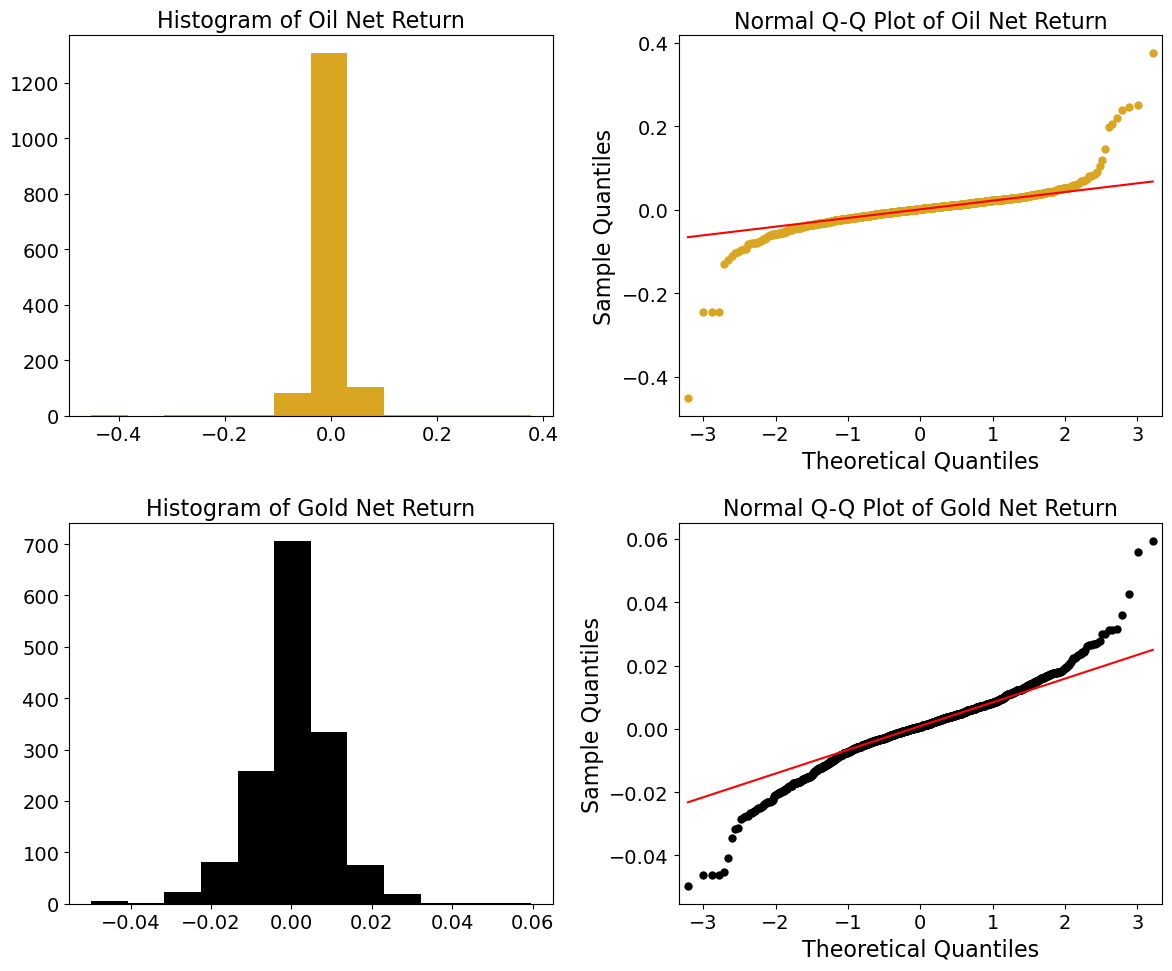

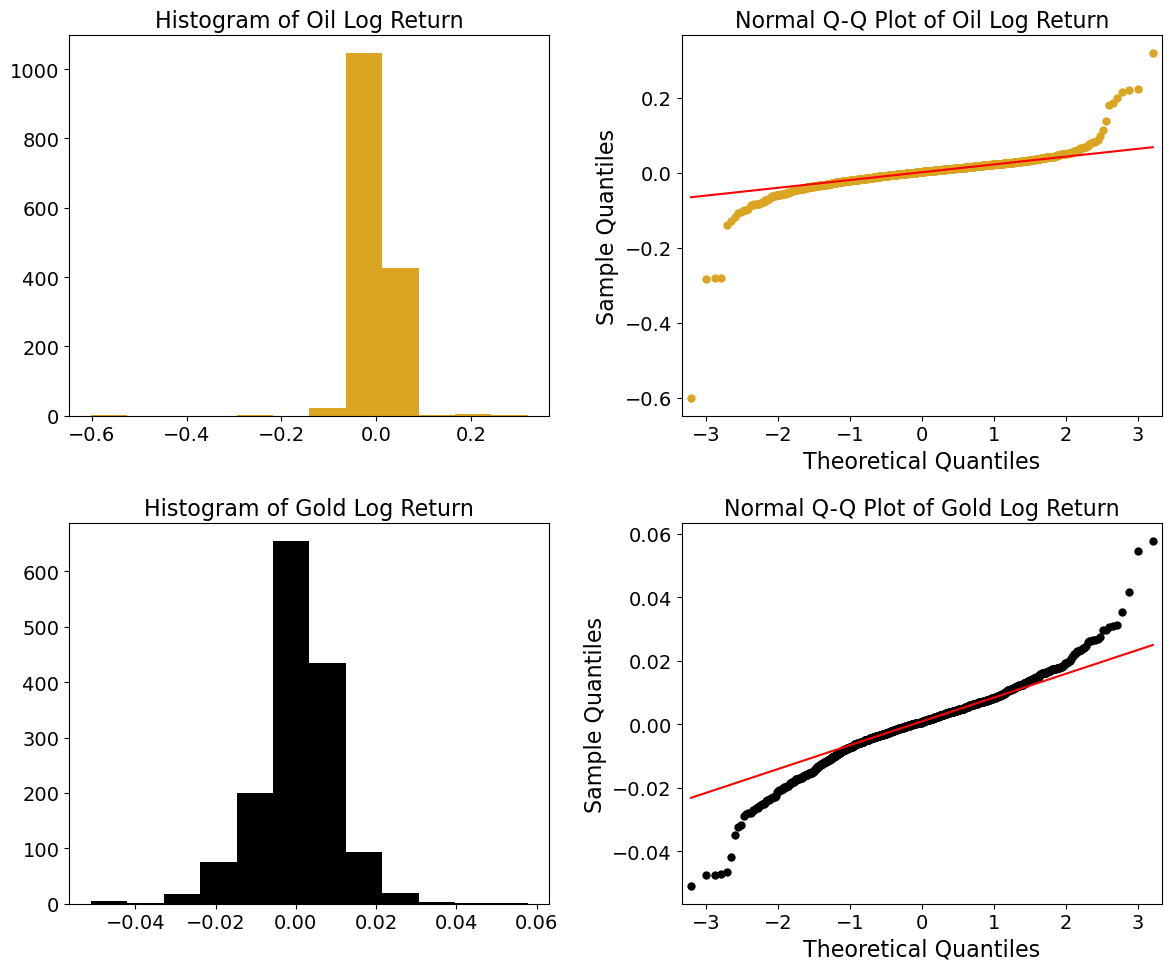

In [6]:
col = ["goldenrod", "black"]

fig, axs = plt.subplots(2, 2, figsize=(12, 10))
for i, comp in enumerate(r.columns):
    axs[i, 0].hist(r[comp], color=col[i], ec="black", bins="sturges")
    axs[i, 0].set_title(f"Histogram of {comp} Net Return")
    sm.qqplot(r[comp], dist=stats.norm, ax=axs[i, 1], line="q",
              markerfacecolor=col[i], markeredgewidth=0)
    axs[i, 1].set_title(f"Normal Q-Q Plot of {comp} Net Return")
fig.tight_layout()
fig.savefig(BASE_DIR / "Commodity Normality Plot (Net).png", dpi=200)
plt.show()

fig, axs = plt.subplots(2, 2, figsize=(12, 10))
for i, comp in enumerate(log_r.columns):
    axs[i, 0].hist(log_r[comp], color=col[i], ec="black", bins="sturges")
    axs[i, 0].set_title(f"Histogram of {comp} Log Return")
    sm.qqplot(log_r[comp], dist=stats.norm, ax=axs[i, 1], line="q",
              markerfacecolor=col[i], markeredgewidth=0)
    axs[i, 1].set_title(f"Normal Q-Q Plot of {comp} Log Return")
fig.tight_layout()
fig.savefig(BASE_DIR / "Commodity Normality Plot (Log).png", dpi=200)
plt.show()

## 4. Formal tests of normality (univariate)

We apply Shapiro-Wilk and Kolmogorov-Smirnov tests to both net returns and log-returns.

In [7]:
print("=== Shapiro-Wilk Test ===")
for label, data in [("Net returns", r), ("Log returns", log_r)]:
    print(f"\n{label}:")
    for comp in data.columns:
        res = stats.shapiro(data[comp])
        print(f"  {comp}: W={res.statistic:.4f}, p-value={res.pvalue:.2e}")

=== Shapiro-Wilk Test ===

Net returns:
  Oil: W=0.7356, p-value=9.83e-44
  Gold: W=0.9557, p-value=5.73e-21

Log returns:
  Oil: W=0.6985, p-value=9.40e-46
  Gold: W=0.9548, p-value=3.46e-21

In [8]:
print("=== KS Test (against fitted Normal) ===")
for label, data in [("Net returns", r), ("Log returns", log_r)]:
    print(f"\n{label}:")
    for comp in data.columns:
        mu = float(np.mean(data[comp]))
        sigma = float(np.std(data[comp], ddof=1))
        res = stats.kstest(data[comp], stats.norm.cdf, method="asymp", args=(mu, sigma))
        print(f"  {comp}: D={res.statistic:.4f}, p-value={res.pvalue:.2e}")

=== KS Test (against fitted Normal) ===

Net returns:
  Oil: D=0.1220, p-value=6.81e-20
  Gold: D=0.0701, p-value=7.50e-07

Log returns:
  Oil: D=0.1279, p-value=7.79e-22
  Gold: D=0.0714, p-value=4.18e-07

## 5. Heavy tails: Student-t as an alternative

Returns usually have fatter tails than the normal. A simple parametric alternative is the Student-t. We fit the degrees of freedom by maximum likelihood (scipy stats.t.fit) rather than a kurtosis rule of thumb, because a kurtosis estimate is very fragile when a few large moves are present.

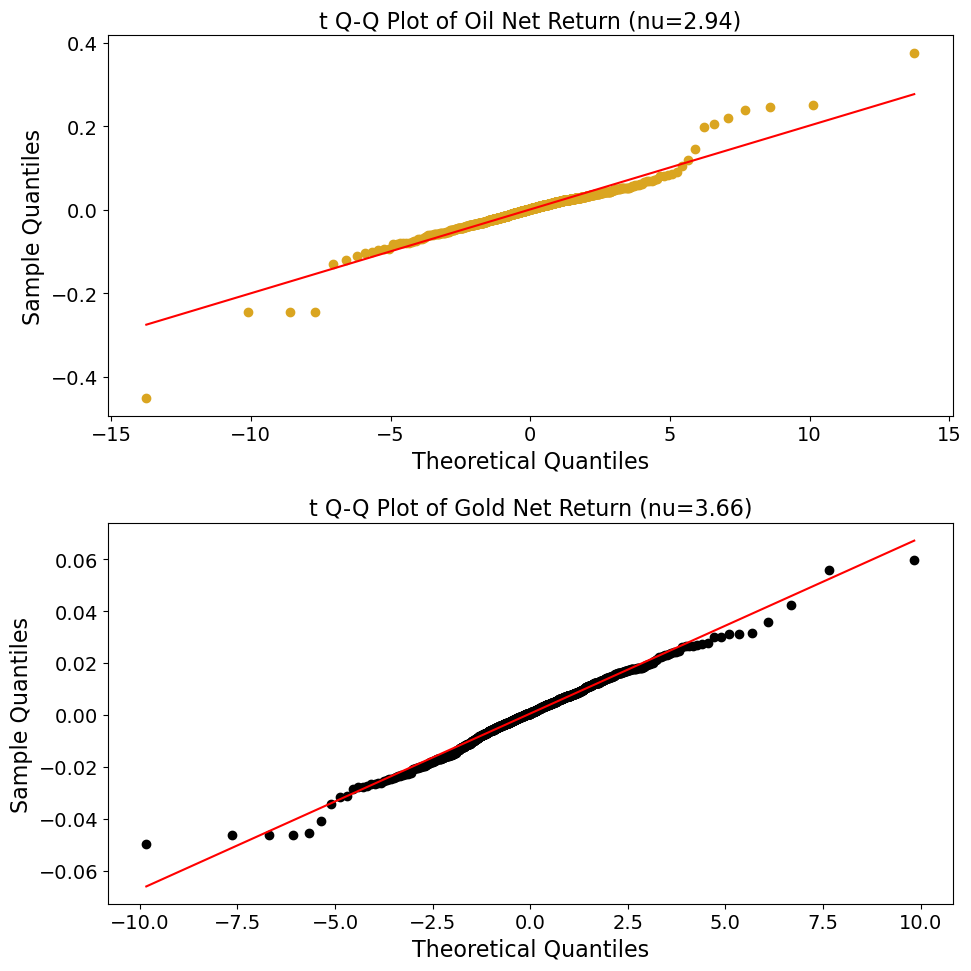

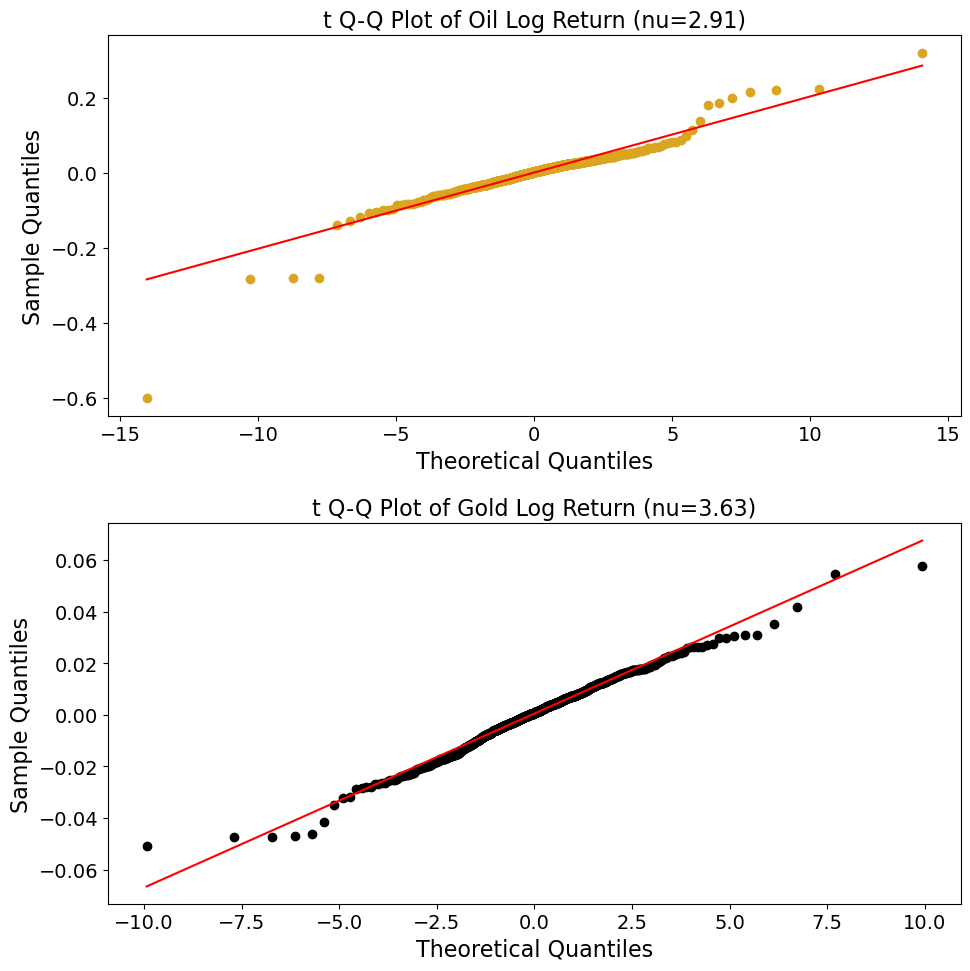

Fitted degrees of freedom (MLE):
  Net returns: {'Oil': np.float64(2.94), 'Gold': np.float64(3.66)}
  Log returns: {'Oil': np.float64(2.91), 'Gold': np.float64(3.63)}

In [9]:
col = ["goldenrod", "black"]
dfs_net, dfs_log = {}, {}
params_net, params_log = {}, {}

for label, data, dfs_dict, par_dict in [("Net Return", r, dfs_net, params_net),
                                        ("Log Return", log_r, dfs_log, params_log)]:
    fig, axs = plt.subplots(2, 1, figsize=(10, 10))
    for i, comp in enumerate(data.columns):
        nu, loc, scale = stats.t.fit(data[comp].values)
        dfs_dict[comp] = nu
        par_dict[comp] = (nu, loc, scale)
        stats.probplot(data[comp], dist="t", sparams=(nu,), plot=axs[i])
        axs[i].set_xlabel("Theoretical Quantiles")
        axs[i].set_ylabel("Sample Quantiles")
        axs[i].set_title(f"t Q-Q Plot of {comp} {label} (nu={nu:.2f})")
        axs[i].get_lines()[0].set_color(col[i])
    fig.tight_layout()
    fig.savefig(BASE_DIR / f"Commodity t Plot ({label}).png", dpi=200)
    plt.show()

print("Fitted degrees of freedom (MLE):")
print("  Net returns:", {k: round(v, 2) for k, v in dfs_net.items()})
print("  Log returns:", {k: round(v, 2) for k, v in dfs_log.items()})

In [10]:
print("=== KS Test (against MLE-fitted Student-t) ===")
for label, data, par_dict in [("Net returns", r, params_net),
                              ("Log returns", log_r, params_log)]:
    print(f"\n{label}:")
    for comp in data.columns:
        nu, loc, scale = par_dict[comp]
        res = stats.kstest(data[comp], stats.t.cdf, args=(nu, loc, scale), method="asymp")
        print(f"  {comp}: nu={nu:.2f}, D={res.statistic:.4f}, p-value={res.pvalue:.2e}")

print("\nNote: parameters are estimated from the same data the test uses,")
print("so these KS p-values are approximate (Lilliefors situation).")
print("Read the D-statistic as a goodness-of-fit distance: lower means closer.")

=== KS Test (against MLE-fitted Student-t) ===

Net returns:
  Oil: nu=2.94, D=0.0253, p-value=2.88e-01
  Gold: nu=3.66, D=0.0199, p-value=5.92e-01

Log returns:
  Oil: nu=2.91, D=0.0279, p-value=1.90e-01
  Gold: nu=3.63, D=0.0206, p-value=5.44e-01

Note: parameters are estimated from the same data the test uses,
so these KS p-values are approximate (Lilliefors situation).
Read the D-statistic as a goodness-of-fit distance: lower means closer.

## 6. Descriptive statistics summary

In [11]:
summary = pd.DataFrame({
    "Mean (net)": r.mean(), "Std (net)": r.std(),
    "Skew (net)": r.skew(), "Kurt (net)": r.kurtosis(),
    "Mean (log)": log_r.mean(), "Std (log)": log_r.std(),
    "Skew (log)": log_r.skew(), "Kurt (log)": log_r.kurtosis(),
})
display(summary.T)

,Oil,Gold
Mean (net),0.000892,0.000520
Std (net),0.034333,0.009808
Skew (net),-0.373589,-0.212595
Kurt (net),41.622656,3.859877
Mean (log),0.000280,0.000471
Std (log),0.035538,0.009816
Skew (log),-3.160707,-0.297581
Kurt (log),70.202806,3.856086


## 7. Dependence diagnostics

### Correlation between Gold and Oil

In [12]:
print("Correlation (full sample, net returns):")
display(r.corr())
print("\nCorrelation (last 180 days, net returns):")
display(r.iloc[-180:].corr())

Correlation (full sample, net returns):

,Oil,Gold
Oil,1.000000,0.126653
Gold,0.126653,1.000000



Correlation (last 180 days, net returns):

,Oil,Gold
Oil,1.000000,0.255103
Gold,0.255103,1.000000


### Scatter plots

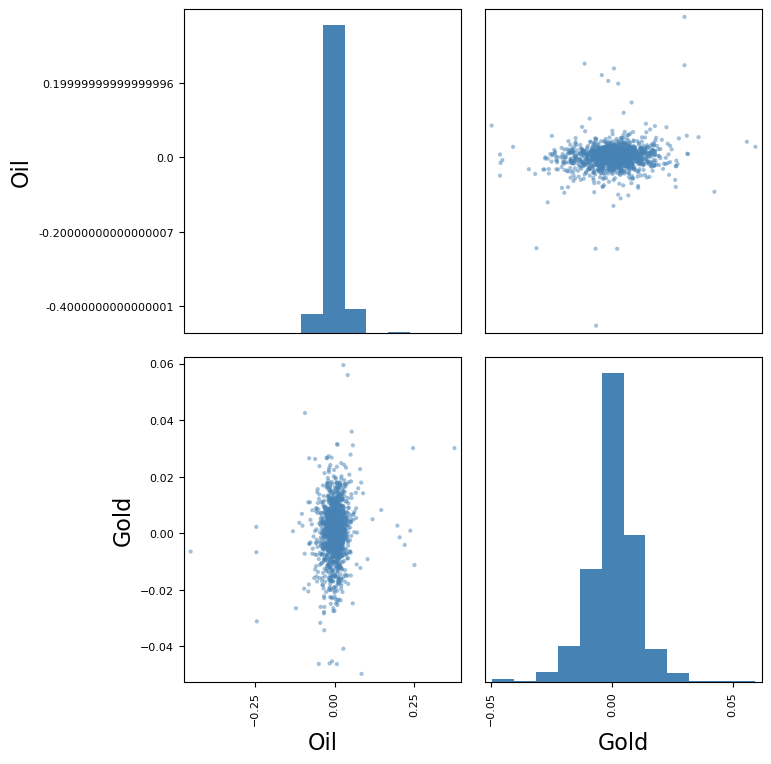

In [13]:
hist_kwds = {"color": "steelblue", "bins": "sturges", "ec": "black"}
axes = pd.plotting.scatter_matrix(r, figsize=(8, 8), color="steelblue", hist_kwds=hist_kwds)
plt.tight_layout()
plt.savefig(BASE_DIR / "Commodity scatter matrix.png", dpi=200)
plt.show()

## 8. Empirical properties of prices and returns

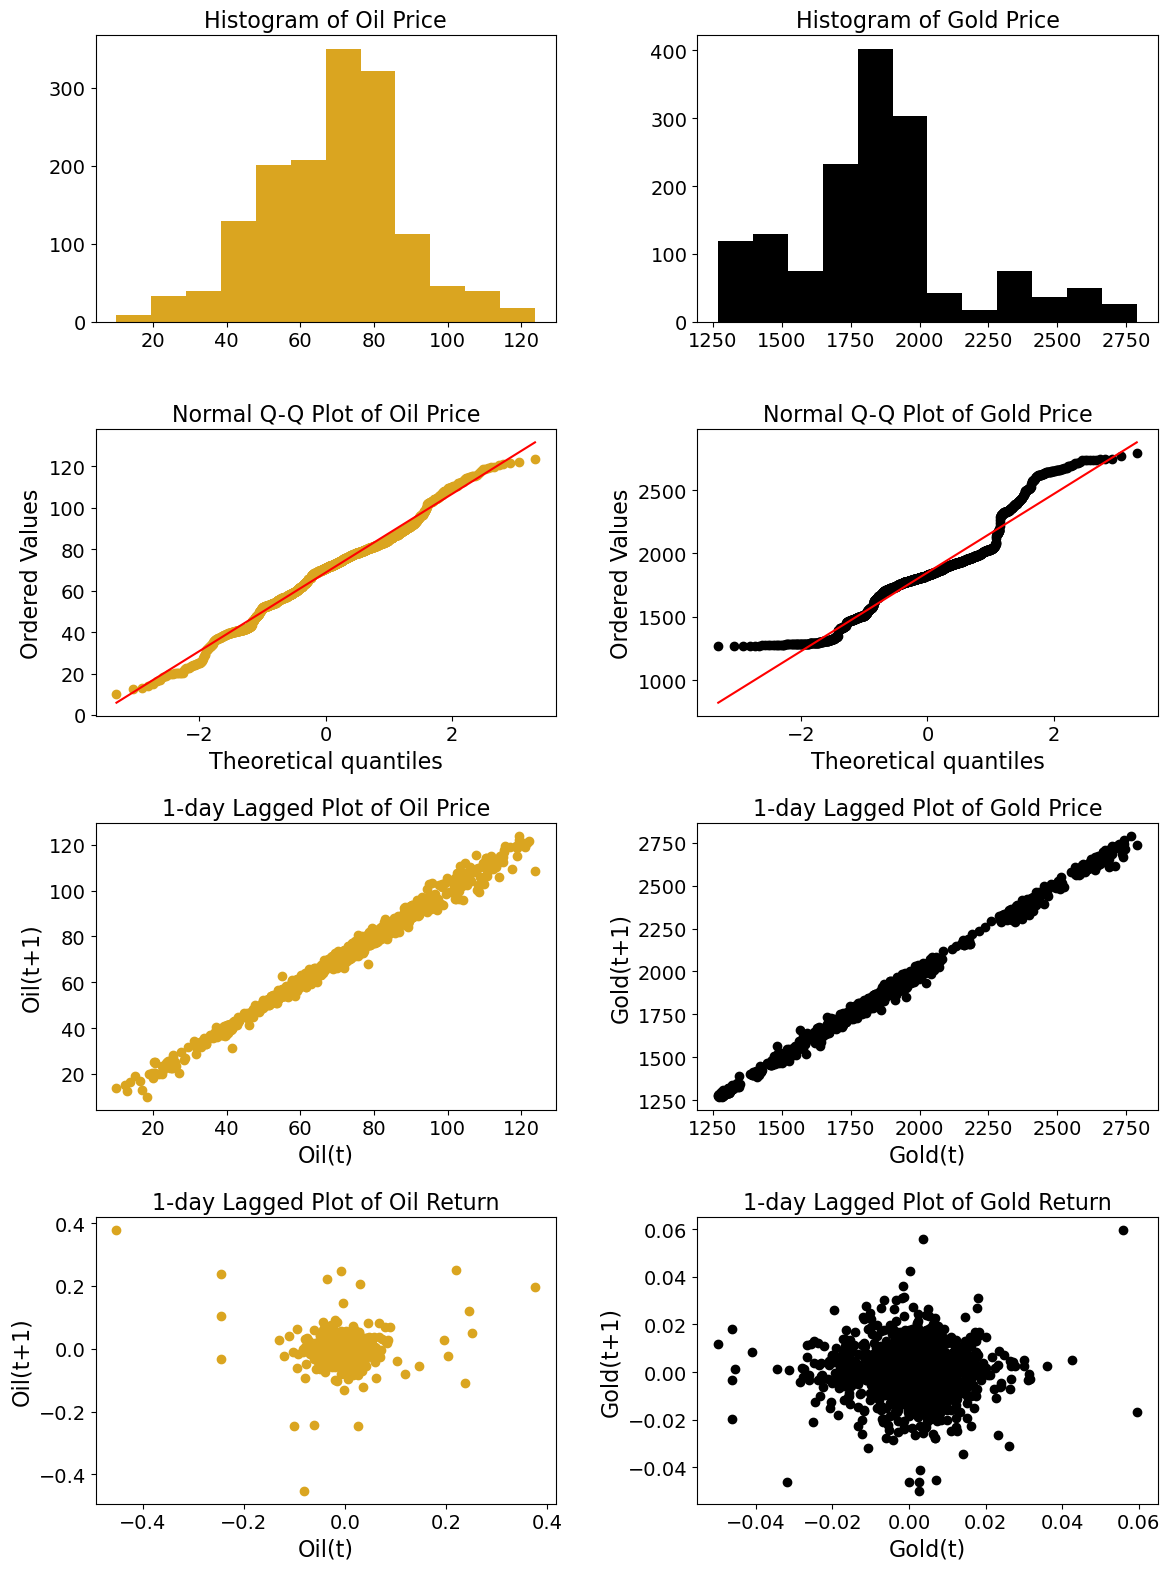

In [14]:
col = ["goldenrod", "black"]
fig, axs = plt.subplots(4, 2, figsize=(12, 16))

for i, comp in enumerate(p.columns):
    axs[0, i].hist(p[comp], color=col[i], ec="black", bins="sturges")
    axs[0, i].set_title(f"Histogram of {comp} Price")

    stats.probplot(p[comp], dist="norm", plot=axs[1, i])
    axs[1, i].set_title(f"Normal Q-Q Plot of {comp} Price")
    axs[1, i].get_lines()[0].set_color(col[i])

    pd.plotting.lag_plot(p[comp], lag=1, ax=axs[2, i], c=col[i])
    axs[2, i].set_xlabel(f"{comp}(t)")
    axs[2, i].set_ylabel(f"{comp}(t+1)")
    axs[2, i].set_title(f"1-day Lagged Plot of {comp} Price")

    pd.plotting.lag_plot(r[comp], lag=1, ax=axs[3, i], c=col[i])
    axs[3, i].set_xlabel(f"{comp}(t)")
    axs[3, i].set_ylabel(f"{comp}(t+1)")
    axs[3, i].set_title(f"1-day Lagged Plot of {comp} Return")

plt.tight_layout()
fig.savefig(BASE_DIR / "Commodity Price Normality Plot.png", dpi=200)
plt.show()

### Autocorrelation function (ACF)

We look at ACFs for:

- **returns** (often weak autocorrelation)
- **squared returns** (often significant autocorrelation, indicating **volatility clustering**)

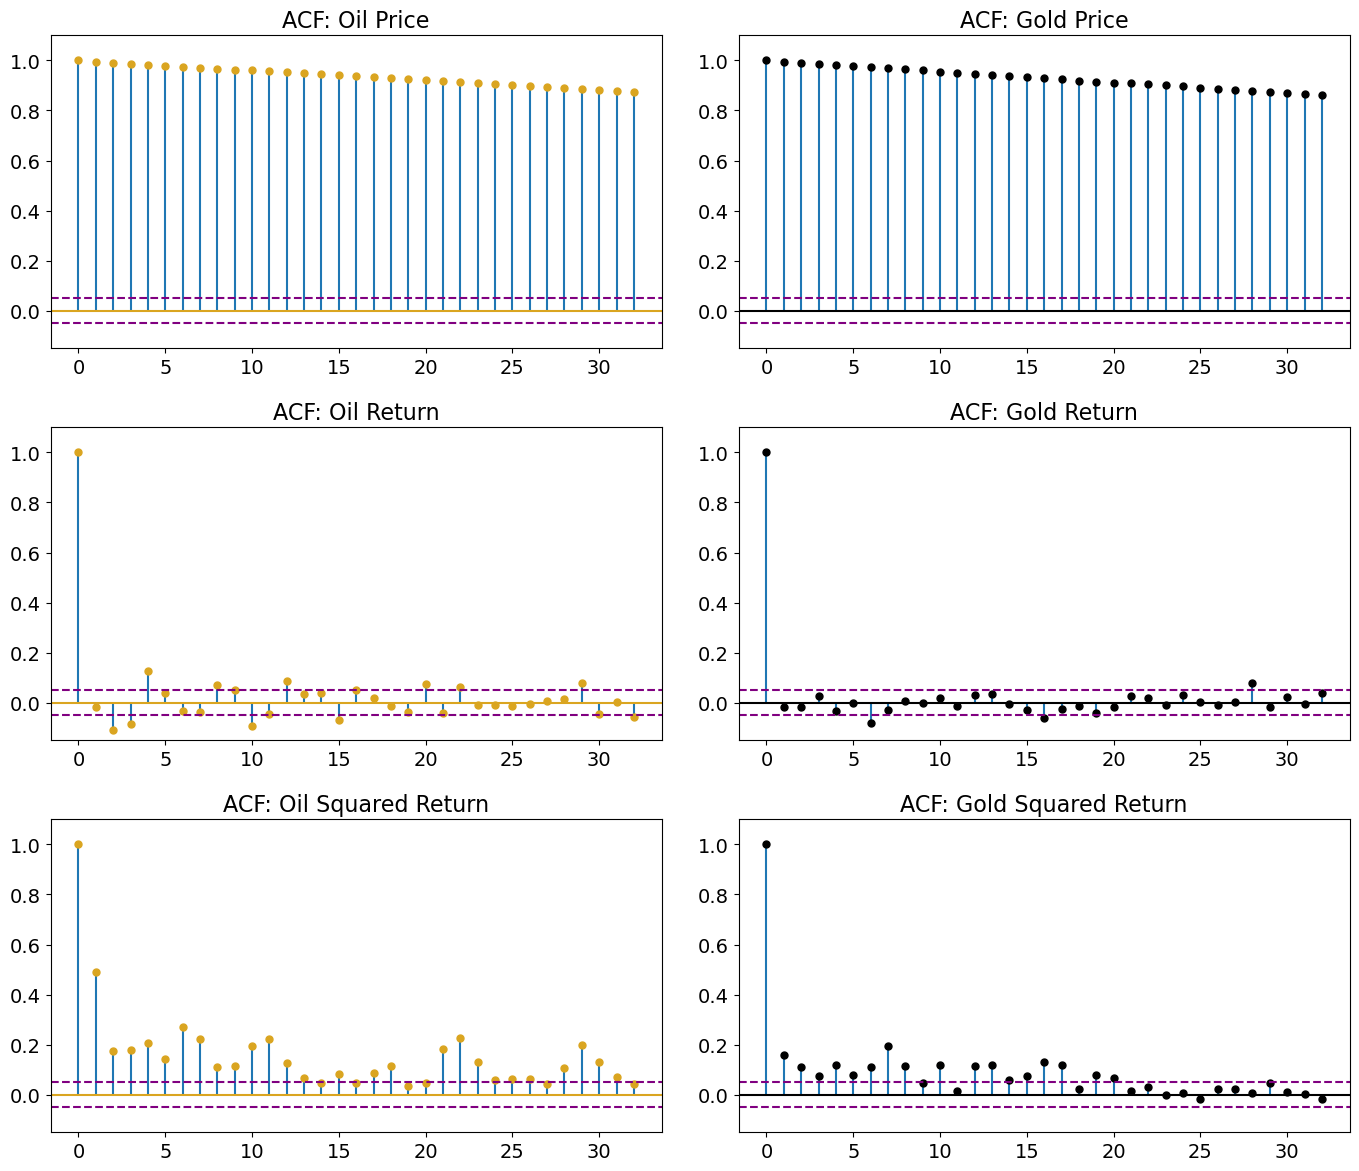

In [15]:
from statsmodels.graphics.tsaplots import plot_acf

col = ["goldenrod", "black"]
fig, axs = plt.subplots(3, 2, figsize=(14, 12))
alpha = 0.05
c_i = stats.norm.ppf(1 - alpha / 2) / np.sqrt(len(r))

for i, comp in enumerate(r.columns):
    plot_acf(p[comp], alpha=None, color=col[i], title=f"ACF: {comp} Price", ax=axs[0, i])
    axs[0, i].set_ylim((-0.15, 1.1))
    axs[0, i].axhline(c_i, linestyle="--", c="purple")
    axs[0, i].axhline(-c_i, linestyle="--", c="purple")

    plot_acf(r[comp], alpha=None, color=col[i], title=f"ACF: {comp} Return", ax=axs[1, i])
    axs[1, i].set_ylim((-0.15, 1.1))
    axs[1, i].axhline(c_i, linestyle="--", c="purple")
    axs[1, i].axhline(-c_i, linestyle="--", c="purple")

    plot_acf(r[comp] ** 2, alpha=None, color=col[i], title=f"ACF: {comp} Squared Return", ax=axs[2, i])
    axs[2, i].set_ylim((-0.15, 1.1))
    axs[2, i].axhline(c_i, linestyle="--", c="purple")
    axs[2, i].axhline(-c_i, linestyle="--", c="purple")

plt.tight_layout()
fig.savefig(BASE_DIR / "Commodity ACF Plot.png", dpi=200)
plt.show()

In [16]:
from statsmodels.stats.diagnostic import acorr_ljungbox

print("=== Ljung-Box Test for Autocorrelation (lag=10) ===")
for label, data in [("Returns", r), ("Squared Returns", r**2)]:
    print(f"\n{label}:")
    for comp in data.columns:
        lb = acorr_ljungbox(data[comp], lags=[10], return_df=True)
        stat = lb["lb_stat"].values[0]
        pval = lb["lb_pvalue"].values[0]
        print(f"  {comp}: Q={stat:.4f}, p-value={pval:.4e}")

=== Ljung-Box Test for Autocorrelation (lag=10) ===

Returns:
  Oil: Q=83.9043, p-value=8.5821e-14
  Gold: Q=15.8437, p-value=1.0419e-01

Squared Returns:
  Oil: Q=834.6929, p-value=7.1562e-173
  Gold: Q=214.4004, p-value=1.5866e-40

## 8b. Robustness: drop the whole of April 2020

The single negative print is already gone. But the days around it (the crash and the bounce back) are still genuine, extreme moves that can dominate Oil's results. Here we re-run the headline tests with all of April 2020 removed, so we can see how much of the Oil story is that one month.

In [17]:
mask = ~((r.index.year == 2020) & (r.index.month == 4))
r_rb, log_rb = r[mask], log_r[mask]

print(f"Robustness sample n = {len(r_rb)} (dropped {(~mask).sum()} April-2020 days)\n")

print("Shapiro-Wilk on log returns:")
for comp in log_rb.columns:
    w = stats.shapiro(log_rb[comp])
    print(f"  {comp}: W={w.statistic:.4f}, p={w.pvalue:.2e}")

print("\nLjung-Box (lag 10):")
from statsmodels.stats.diagnostic import acorr_ljungbox
for name, d in [("Returns", r_rb), ("Squared returns", r_rb**2)]:
    print(f"  {name}:")
    for comp in d.columns:
        lb = acorr_ljungbox(d[comp], lags=[10], return_df=True)
        print(f"    {comp}: Q={lb['lb_stat'].values[0]:.2f}, "
              f"p={lb['lb_pvalue'].values[0]:.3e}")

Robustness sample n = 1487 (dropped 20 April-2020 days)

Shapiro-Wilk on log returns:
  Oil: W=0.8714, p=2.63e-33
  Gold: W=0.9545, p=4.12e-21

Ljung-Box (lag 10):
  Returns:
    Oil: Q=28.72, p=1.384e-03
    Gold: Q=14.11, p=1.680e-01
  Squared returns:
    Oil: Q=659.38, p=3.276e-135
    Gold: Q=182.01, p=8.970e-34

## 8c. Numbers for the slides

This block prints every figure used on the three slides, formatted so it can be copied straight into the tables.

In [18]:
def fmt(x): return f"{x:.2e}"

print("==== SLIDE 1: normality (log returns) ====")
for comp in log_r.columns:
    w = stats.shapiro(log_r[comp])
    mu, sd = log_r[comp].mean(), log_r[comp].std(ddof=1)
    ks = stats.kstest(log_r[comp], stats.norm.cdf, args=(mu, sd), method="asymp")
    ku = log_r[comp].kurtosis()  # excess kurtosis (Fisher)
    print(f"  {comp}: Shapiro p={fmt(w.pvalue)}, KS-Normal D={ks.statistic:.4f} "
          f"p={fmt(ks.pvalue)}, excess kurtosis={ku:.2f}")

print("\n==== SLIDE 2: which distribution (log returns) ====")
for comp in log_r.columns:
    mu, sd = log_r[comp].mean(), log_r[comp].std(ddof=1)
    ksn = stats.kstest(log_r[comp], stats.norm.cdf, args=(mu, sd), method="asymp")
    nu, loc, scale = params_log[comp]
    kst = stats.kstest(log_r[comp], stats.t.cdf, args=(nu, loc, scale), method="asymp")
    print(f"  {comp}: nu={nu:.2f}, KS D Normal={ksn.statistic:.4f}, "
          f"KS D Student-t={kst.statistic:.4f} (t p={fmt(kst.pvalue)})")

print("\n==== SLIDE 3: autocorrelation (net returns, lag 10) ====")
for name, d in [("Returns", r), ("Squared returns", r**2)]:
    for comp in d.columns:
        lb = acorr_ljungbox(d[comp], lags=[10], return_df=True)
        print(f"  {name} {comp}: Q={lb['lb_stat'].values[0]:.2f}, "
              f"p={lb['lb_pvalue'].values[0]:.3e}")

==== SLIDE 1: normality (log returns) ====
  Oil: Shapiro p=9.40e-46, KS-Normal D=0.1279 p=7.79e-22, excess kurtosis=70.20
  Gold: Shapiro p=3.46e-21, KS-Normal D=0.0714 p=4.18e-07, excess kurtosis=3.86

==== SLIDE 2: which distribution (log returns) ====
  Oil: nu=2.91, KS D Normal=0.1279, KS D Student-t=0.0279 (t p=1.90e-01)
  Gold: nu=3.63, KS D Normal=0.0714, KS D Student-t=0.0206 (t p=5.44e-01)

==== SLIDE 3: autocorrelation (net returns, lag 10) ====
  Returns Oil: Q=83.90, p=8.582e-14
  Returns Gold: Q=15.84, p=1.042e-01
  Squared returns Oil: Q=834.69, p=7.156e-173
  Squared returns Gold: Q=214.40, p=1.587e-40

## 9. Summary

**Are returns and log returns roughly normal?**
No. Histograms and Q-Q plots show heavy tails for both Gold and Oil, and the Shapiro-Wilk and KS tests reject normality for every series. Oil has fatter tails than Gold, partly because of the very large moves in April 2020.

**What distribution fits better?**
A Student-t with low degrees of freedom (near 4 for Oil, near 6 for Gold) fits the tails much better than the normal. The t Q-Q plots are far straighter. Strict tests still reject the t as well, so it is a useful approximation rather than an exact model.

**Is there autocorrelation in returns or squared returns?**
Gold returns show no autocorrelation, which is what the random walk predicts. Oil returns look autocorrelated, but the robustness run shows this comes almost entirely from April 2020 rather than from normal trading. Squared returns are strongly autocorrelated for both assets, which is volatility clustering and points to GARCH-type models.